# Training a combat policy with reinforcement learning

This notebook trains a MaskablePPO policy through a staged curriculum (Acts 1 and 4 trained in alternation, then Acts 2 and 3), gates progression on fixed-seed win rates, saves resumable stage state, and compares the policy with baseline heuristics.

Install the optional training and plotting dependencies before running:

```bash
uv sync --extra rl --extra notebook
```

In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / 'sts2_env').exists():
    ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'sts2_env').exists())
sys.path.insert(0, str(ROOT))

import numpy as np
from sb3_contrib import MaskablePPO
from stable_baselines3.common.callbacks import CallbackList
import sts2_env.encounters.act1 as act1
import sts2_env.encounters.act4 as act4
from sts2_env.heuristic_plotter import CombatHeuristicPlotter
from sts2_env.rl_training import (
    RewardConfig,
    create_training_run_dir,
    evaluate_policy_against_heuristics,
    evaluate_training_policy,
    load_training_metadata,
    make_progress_callback,
    make_training_env,
    make_training_metrics_callback,
    save_training_metadata,
)
from sts2_env.rl_training_plotter import plot_training_history, read_training_history


## Configure training

The curriculum has three stages: Acts 1 and 4 are trained together, with the environment choosing a random starting act and alternating acts after each episode; Acts 2 and 3 follow. Each stage samples the selected act's full encounter pool and uses the act/type-specific generated deck. A stage unlocks the next only when its fixed-seed win rate reaches the configured target; `TRAIN_ENCOUNTERS` is used only for the separate heuristic comparison.

In [ ]:
CHARACTER_ID = 'Ironclad'  # Ironclad, Silent, Defect, Necrobinder, Regent
TRAIN_ENCOUNTERS = act4.WEAK_ENCOUNTERS
CURRICULUM_STAGES = [(1, (1, 4)), (2, (2,)), (3, (3,))]
CURRICULUM_ACTS = [act for _, stage_acts in CURRICULUM_STAGES for act in stage_acts]
CURRICULUM_WIN_RATE_TARGETS = {1: 0.65, 2: 0.55, 3: 0.45}
STAGE_TIMESTEPS = 100_000  # additional steps per stage and per notebook run

REWARDS = RewardConfig(
    damage_dealt=1.0,
    damage_received=-3.0,
    win=50.0,
    death=-100.0,
    per_turn=-5.0,
    wasted_block=-0.5,
)

TRAINING_SEED = 20261108
PROGRESS_INTERVAL = 10_000
MAX_COMBAT_TURNS = 200
MODEL_PATH = ROOT / 'models' / f'combat_maskable_ppo_{CHARACTER_ID.lower()}'
EXISTING_MODEL_PATH = MODEL_PATH  # Change this to continue a different saved model
TRAINING_LOG_ROOT = MODEL_PATH.parent / f'{MODEL_PATH.name}_logs'
PERIODIC_EVALUATION_INTERVAL = 20_000
PERIODIC_EVALUATION_GAMES = 32
PERIODIC_EVALUATION_SEED = 20261110


In [3]:
TRAIN_MODE = 'load'  # 'new', 'continue', or 'load'

if TRAIN_MODE not in {'new', 'continue', 'load'}:
    raise ValueError(f'Unsupported TRAIN_MODE: {TRAIN_MODE}')

## Train, continue, or load the policy

`TRAIN_MODE = 'new'` starts from scratch. Use `'continue'` to resume the current curriculum stage from `EXISTING_MODEL_PATH`, or `'load'` to skip training and evaluate the existing model. A stage receives `STAGE_TIMESTEPS` per run; it must meet its fixed-seed target before the notebook unlocks the next stage. If it misses, save and continue the same stage in a later run. The first stage alternates Acts 1 and 4 after every episode.

Training and evaluation CSV files are saved under `TRAINING_LOG_ROOT`; model metadata records this location. Each session also writes `card_performance.csv`: per-card mean HP lost when the card is in the deck or played, with separate encounter rows and act/type aggregates (for example one combined Act 1 Weak row per card). TensorBoard also receives SB3 losses and custom combat metrics. For live monitoring, start TensorBoard in a terminal with `tensorboard --logdir <TRAINING_LOG_ROOT>`. The notebook plots the persisted history after training or loading.


### Session and curriculum state

These helpers load saved progress, create repeatable evaluation seeds, and determine which stage should run next.

In [ ]:
def prepare_training_session():
    """Load run metadata, create fixed evaluation seeds, and prepare log paths."""
    global TRAINING_LOG_ROOT

    model_metadata = None
    if TRAIN_MODE in {"continue", "load"}:
        metadata_path = EXISTING_MODEL_PATH.with_suffix(".json")
        if metadata_path.is_file():
            model_metadata = load_training_metadata(EXISTING_MODEL_PATH)
        if model_metadata and model_metadata.get("training_log_dir"):
            TRAINING_LOG_ROOT = Path(model_metadata["training_log_dir"])
        else:
            TRAINING_LOG_ROOT = EXISTING_MODEL_PATH.parent / f"{EXISTING_MODEL_PATH.stem}_logs"
            print("No previous training history is recorded; only new runs will be plotted.")

    evaluation_seeds = np.random.default_rng(PERIODIC_EVALUATION_SEED).integers(
        0,
        2**31 - 1,
        size=PERIODIC_EVALUATION_GAMES,
        dtype=np.int64,
    ).tolist()
    run_dir = (
        create_training_run_dir(TRAINING_LOG_ROOT)
        if TRAIN_MODE in {"new", "continue"}
        else None
    )
    return model_metadata, evaluation_seeds, run_dir


def load_curriculum_state(model_metadata):
    """Validate checkpoint metadata and return resumable curriculum progress."""
    if TRAIN_MODE != "continue":
        return {
            "completed_acts": [],
            "current_stage": tuple(CURRICULUM_STAGES[0][1]),
            "current_stage_id": CURRICULUM_STAGES[0][0],
            "stage_timesteps": 0,
        }

    if not EXISTING_MODEL_PATH.exists() and not Path(f"{EXISTING_MODEL_PATH}.zip").exists():
        raise FileNotFoundError(f"Existing model not found: {EXISTING_MODEL_PATH}")
    if model_metadata and model_metadata.get("training_acts"):
        if model_metadata["training_acts"] != CURRICULUM_ACTS:
            raise ValueError("Saved model curriculum does not match CURRICULUM_ACTS")

    expected_stages = [list(stage_acts) for _, stage_acts in CURRICULUM_STAGES]
    if model_metadata and model_metadata.get("training_stages"):
        if model_metadata["training_stages"] != expected_stages:
            raise ValueError("Saved model stages do not match CURRICULUM_STAGES")

    completed_acts = list((model_metadata or {}).get("completed_training_acts", []))
    current_stage_id = (model_metadata or {}).get("current_training_act")
    saved_stage = (model_metadata or {}).get("current_training_stage")
    current_stage = tuple(saved_stage) if saved_stage else None
    if current_stage is None and current_stage_id is not None:
        current_stage = (1, 4) if current_stage_id in {1, 4} else (current_stage_id,)

    return {
        "completed_acts": completed_acts,
        "current_stage": current_stage,
        "current_stage_id": current_stage_id,
        "stage_timesteps": int((model_metadata or {}).get("current_act_timesteps", 0)),
    }


def get_remaining_curriculum_stages(state):
    """Return unfinished stages, beginning with the saved in-progress stage."""
    remaining = [
        (stage_id, tuple(stage_acts))
        for stage_id, stage_acts in CURRICULUM_STAGES
        if not set(stage_acts).issubset(state["completed_acts"])
    ]
    current_stage = state["current_stage"]
    if current_stage is not None:
        stage_options = [stage_acts for _, stage_acts in remaining]
        if current_stage not in stage_options:
            raise ValueError(f"Invalid saved curriculum stage: {current_stage}")
        remaining = remaining[stage_options.index(current_stage):]
    return remaining

### Train and save one stage

Model setup, stage training/evaluation, curriculum updates, and checkpoint writes are kept in separate functions.

In [ ]:
def create_or_attach_model(model, training_env):
    """Load, initialize, or attach the PPO model to the current stage env."""
    if model is None and TRAIN_MODE == "continue":
        model = MaskablePPO.load(
            str(EXISTING_MODEL_PATH),
            env=training_env,
            tensorboard_log=str(TRAINING_LOG_ROOT),
        )
        print(f"Resuming training from {model.num_timesteps:,} total steps")
    elif model is None:
        model = MaskablePPO(
            "MlpPolicy",
            training_env,
            seed=TRAINING_SEED,
            n_steps=512,
            batch_size=64,
            verbose=0,
            tensorboard_log=str(TRAINING_LOG_ROOT),
        )
    else:
        model.set_env(training_env)
    return model


def train_one_stage(model, training_env, stage_log_dir, training_acts):
    """Train for one stage budget and return its fixed-seed evaluation metrics."""
    starting_timesteps = model.num_timesteps
    callbacks = CallbackList([
        make_progress_callback(
            STAGE_TIMESTEPS,
            log_interval=PROGRESS_INTERVAL,
            start_timesteps=starting_timesteps,
        ),
        make_training_metrics_callback(
            stage_log_dir,
            evaluation_seeds=periodic_evaluation_seeds,
            evaluation_interval=PERIODIC_EVALUATION_INTERVAL,
            evaluation_training_acts=training_acts,
            character_id=CHARACTER_ID,
            reward_config=REWARDS,
            max_turns=MAX_COMBAT_TURNS,
            start_timesteps=starting_timesteps,
        ),
    ])
    stage_label = "-".join(str(act) for act in training_acts)
    model.learn(
        total_timesteps=STAGE_TIMESTEPS,
        reset_num_timesteps=(TRAIN_MODE == "new" and model.num_timesteps == 0),
        tb_log_name=f"combat_acts_{stage_label}",
        callback=callbacks,
    )
    return evaluate_training_policy(
        model,
        seeds=periodic_evaluation_seeds,
        training_acts=training_acts,
        character_id=CHARACTER_ID,
        reward_config=REWARDS,
        max_turns=MAX_COMBAT_TURNS,
    )


def advance_curriculum_state(state, remaining_stages, stage_index, stage_id, training_acts, passed):
    """Mark a successful stage complete or retain it for the next run."""
    if passed:
        state["completed_acts"].extend(
            act for act in training_acts if act not in state["completed_acts"]
        )
        next_index = stage_index + 1
        next_stage = remaining_stages[next_index] if next_index < len(remaining_stages) else None
        state["current_stage_id"] = next_stage[0] if next_stage else None
        state["current_stage"] = next_stage[1] if next_stage else None
        state["stage_timesteps"] = 0
    else:
        state["current_stage_id"] = stage_id
        state["current_stage"] = tuple(training_acts)
        state["stage_timesteps"] += STAGE_TIMESTEPS
    return state


def save_curriculum_checkpoint(model, state, run_dir):
    """Save PPO weights and enough metadata to resume the same curriculum."""
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    model.save(str(MODEL_PATH))
    metadata_path = save_training_metadata(
        MODEL_PATH.with_suffix(".zip"),
        character_id=CHARACTER_ID,
        encounters=None,
        reward_config=REWARDS,
        seed=TRAINING_SEED,
        total_timesteps=model.num_timesteps,
        training_log_dir=TRAINING_LOG_ROOT,
        run_log_dir=run_dir,
        training_acts=CURRICULUM_ACTS,
        training_stages=[list(stage_acts) for _, stage_acts in CURRICULUM_STAGES],
        completed_training_acts=state["completed_acts"],
        current_training_act=state["current_stage_id"],
        current_training_stage=state["current_stage"],
        current_act_timesteps=state["stage_timesteps"],
    )
    print(f"Model and curriculum checkpoint saved to {MODEL_PATH}.zip")
    print(f"Training metadata saved to {metadata_path}")

### Run or load the policy

The orchestration function below is intentionally small: it coordinates the helpers above and closes each environment.

In [ ]:
def run_training_curriculum():
    """Run each unlocked stage, saving a resumable checkpoint after evaluation."""
    state = load_curriculum_state(model_metadata)
    remaining_stages = get_remaining_curriculum_stages(state)
    model = None

    if TRAIN_MODE == "continue" and not remaining_stages:
        model = MaskablePPO.load(str(EXISTING_MODEL_PATH))
        print("Curriculum already complete; loaded the latest checkpoint.")

    for stage_index, (stage_id, training_acts) in enumerate(remaining_stages):
        stage_label = "-".join(str(act) for act in training_acts)
        stage_log_dir = training_run_dir / f"acts-{stage_label}"
        training_env = make_training_env(
            training_acts=training_acts,
            character_id=CHARACTER_ID,
            reward_config=REWARDS,
            max_turns=MAX_COMBAT_TURNS,
            log_dir=stage_log_dir,
        )
        try:
            model = create_or_attach_model(model, training_env)
            metrics = train_one_stage(model, training_env, stage_log_dir, training_acts)
            target_win_rate = CURRICULUM_WIN_RATE_TARGETS[stage_id]
            passed = metrics["win_rate"] >= target_win_rate
            print(
                f"Acts {stage_label}: win rate {metrics['win_rate']:.1%} "
                f"(unlock target {target_win_rate:.1%})"
            )

            advance_curriculum_state(
                state, remaining_stages, stage_index, stage_id, training_acts, passed
            )
            save_curriculum_checkpoint(model, state, training_run_dir)
            if not passed:
                print("Next stage remains locked. Choose TRAIN_MODE = 'continue' to retry.")
                break
        finally:
            training_env.close()

    if state["current_stage"] is None:
        print("Curriculum complete: all configured acts reached their win-rate targets.")
    print(f"Training logs saved to {TRAINING_LOG_ROOT}")
    return model


def load_policy_for_evaluation():
    """Load a trained combat policy without starting another training run."""
    if not EXISTING_MODEL_PATH.exists() and not Path(f"{EXISTING_MODEL_PATH}.zip").exists():
        raise FileNotFoundError(f"Existing model not found: {EXISTING_MODEL_PATH}")
    model = MaskablePPO.load(str(EXISTING_MODEL_PATH))
    print(f"Loaded model from {EXISTING_MODEL_PATH}")
    return model

In [ ]:
model_metadata, periodic_evaluation_seeds, training_run_dir = prepare_training_session()

In [ ]:
if TRAIN_MODE in {"new", "continue"}:
    model = run_training_curriculum()
else:
    model = load_policy_for_evaluation()

## Training history

Episode metrics and periodic fixed-seed evaluations are persisted as CSV. This cell displays history after training or loading a model with saved logs.

In [6]:
if list(TRAINING_LOG_ROOT.rglob('episodes.csv')):
    training_history = read_training_history(TRAINING_LOG_ROOT)
    plot_training_history(TRAINING_LOG_ROOT, window=50)
else:
    print('No persisted training history is available for this model yet.')


No persisted training history is available for this model yet.


## Compare against baseline heuristics

Each evaluation seed is paired with an encounter from the selected list. The trained policy and all three heuristics run the exact same encounter/seed pair. Change `NUM_EVALUATION_GAMES` to adjust the comparison size.

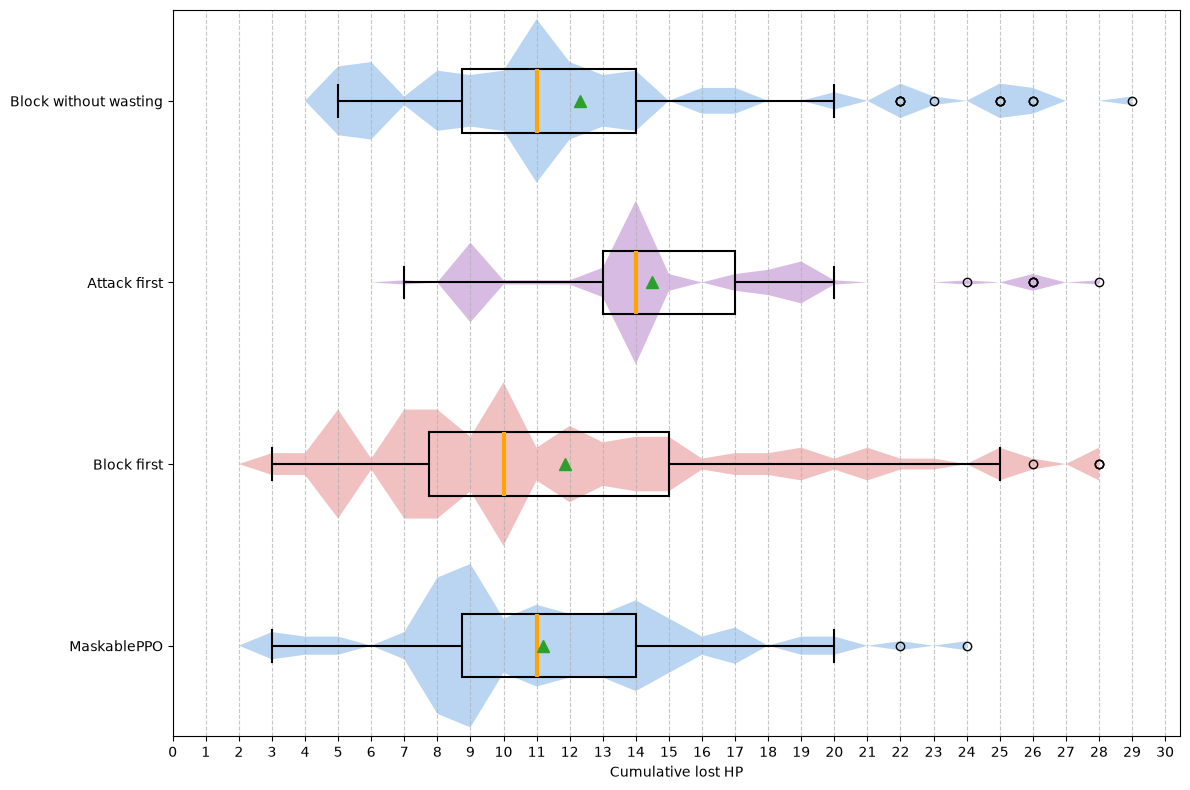

(<Figure size 1200x800 with 1 Axes>, <Axes: xlabel='Cumulative lost HP'>)

In [7]:
NUM_EVALUATION_GAMES = 100
EVALUATION_SEED = 20261109

evaluation_seeds = np.random.default_rng(EVALUATION_SEED).integers(
    0,
    2**31 - 1,
    size=NUM_EVALUATION_GAMES,
    dtype=np.int64,
).tolist()
results = evaluate_policy_against_heuristics(
    model,
    TRAIN_ENCOUNTERS,
    evaluation_seeds,
    character_id=CHARACTER_ID,
    max_steps=MAX_COMBAT_TURNS * 10,
)

CombatHeuristicPlotter.plot(results)

### Compare harder combats

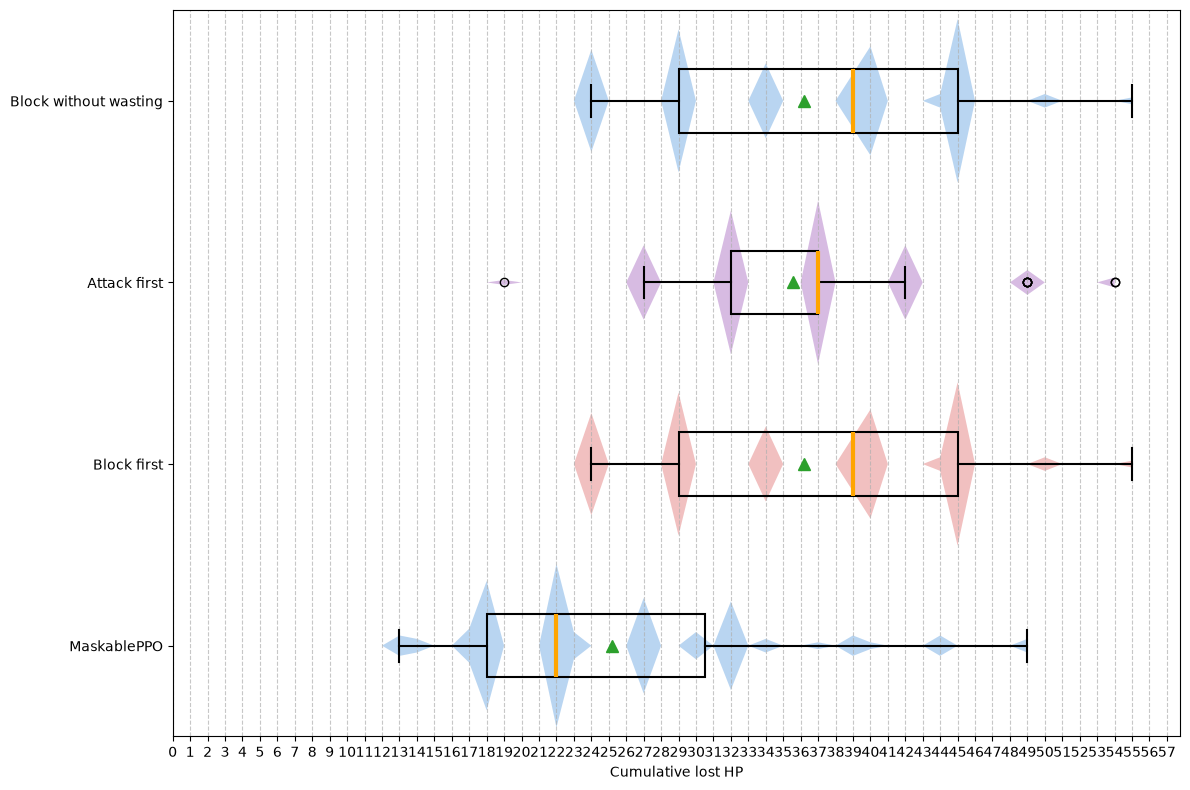

(<Figure size 1200x800 with 1 Axes>, <Axes: xlabel='Cumulative lost HP'>)

In [8]:
NUM_EVALUATION_GAMES = 100
EVALUATION_SEED = 20261109

evaluation_seeds = np.random.default_rng(EVALUATION_SEED).integers(
    0,
    2**31 - 1,
    size=NUM_EVALUATION_GAMES,
    dtype=np.int64,
).tolist()
results = evaluate_policy_against_heuristics(
    model,
    [setup_sewer_clam_normal],
    evaluation_seeds,
    character_id=CHARACTER_ID,
    max_steps=MAX_COMBAT_TURNS * 10,
)

CombatHeuristicPlotter.plot(results)